AI-AUV CH4探索 3方針比較

設定パラメタ
- 真の海底発生源: `(170, 140) m`
- 潮流: `0.22 m/s, 35 deg`
- SEARCH高度での解析的なプルーム中心: 約 `(272, 212) m`
- 共通初期トランセクト: `(400,300) → (365,350) → (330,390) → (285,405) m`

初期トランセクトは真の発生源位置をアルゴリズムに与えるものではなく、既知の潮流方向と調査境界に基づく下流側の広域偵察線です。その後の次地点選択だけが3方式で異なる。

最終画面には、白いXの推定源、緑の星の真の源、シアンのひし形のSEARCH高度における期待プルーム中心、潮流移流線、推定誤差線を表示する。


In [ ]:
# Google Colab setup
!pip -q install "genesis-world>=1.4.0,<1.5" scikit-learn imageio imageio-ffmpeg matplotlib pillow
import genesis as gs
print("Genesis World version:", getattr(gs, "__version__", "unknown"))


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Genesis World version: 1.4.5


## 実装本体


In [ ]:
# -*- coding: utf-8 -*-
"""Vectorized Colab implementation: Random vs Analytic vs Physics+RF residual."""
from dataclasses import dataclass
from pathlib import Path
import math, time, warnings
import numpy as np
warnings.filterwarnings('ignore', category=DeprecationWarning, module=r'quadrants\..*')

@dataclass
class Cfg:
    seed:int=42
    out:str='/content' if Path('/content').exists() else '.'
    domain:float=420.; grid_n:int=21; source:tuple=(170.,140.)
    depth:float=180.; alt_search:float=38.; alt_confirm:float=16.
    current:float=.22; current_deg:float=35.; rise:float=.25
    background:float=.03; strength:float=1.08; noise:float=.025
    max_obs:int=18; max_leg:float=88.; detect:float=.43; confirm:float=.35
    need_high:int=2; success_radius:float=35.
    n_train:int=10000; n_trees:int=100; rf_depth:int=14
    benchmark_trials:int=5; top_k:int=30
    fps:int=8; turn_frames:int=5; move_frames:int=20; scan_frames:int=10
    camera_res:tuple=(480,320); world_scale:float=10/420
    z_search:float=2.4; z_confirm:float=1.2

class Models:
    def __init__(self,c): self.c=c
    @staticmethod
    def basis(deg):
        t=np.deg2rad(np.asarray(deg)); return np.c_[np.cos(t),np.sin(t)],np.c_[-np.sin(t),np.cos(t)]
    def base_pairs(self,xy,src,alt,depth,current,deg):
        """Row-wise pairs: xy[i] is evaluated for src[i]. All inputs broadcast to n."""
        p=np.atleast_2d(xy).astype(float); s=np.atleast_2d(src).astype(float); n=len(p)
        def arr(v): return np.full(n,v,float) if np.ndim(v)==0 else np.asarray(v,float)
        alt,depth,current,deg=map(arr,(alt,depth,current,deg));u,nn=self.basis(deg)
        rise_t=np.maximum(1.,depth-alt)/self.c.rise; drift=current*rise_t;surv=np.exp(-.0010*rise_t)
        center=s+drift[:,None]*u;d=p-center;along=np.sum(d*u,axis=1);cross=np.sum(d*nn,axis=1);sig=15.+.04*drift
        return self.c.background+self.c.strength*surv*np.exp(-.5*(along/44.)**2-.5*(cross/sig)**2)
    def base_grid(self,points,src,alt):
        p=np.atleast_2d(points);s=np.repeat(np.asarray(src)[None,:],len(p),axis=0)
        return self.base_pairs(p,s,alt,self.c.depth,self.c.current,self.c.current_deg)
    def truth_pairs(self,xy,src,alt,phase,depth,current,deg):
        p=np.atleast_2d(xy).astype(float);s=np.atleast_2d(src).astype(float);n=len(p)
        def arr(v): return np.full(n,v,float) if np.ndim(v)==0 else np.asarray(v,float)
        alt,phase,depth,current,deg=map(arr,(alt,phase,depth,current,deg))
        b=self.base_pairs(p,s,alt,depth,current,deg)
        true_deg=deg+12*np.sin(phase)+.045*(depth-alt);u,nn=self.basis(true_deg)
        rt=np.maximum(1.,depth-alt)/self.c.rise;drift=current*(1+.14*np.sin(phase))*rt
        ctr=s+drift[:,None]*u+9*np.sin(phase)[:,None]*nn;d=p-ctr
        along=np.sum(d*u,axis=1);cross=np.sum(d*nn,axis=1)
        nonlinear=.18*np.exp(-.5*(along/70.)**2-.5*((cross-12*np.sin(phase))/24.)**2)
        terrain=.06*np.sin((p[:,0]+.7*p[:,1])/75.)*np.exp(-np.linalg.norm(d,axis=1)/180.)
        return np.clip(b+nonlinear+terrain,0,None)
    def truth(self,points,src,alt,phase=1.1):
        p=np.atleast_2d(points);s=np.repeat(np.asarray(src)[None,:],len(p),axis=0)
        return self.truth_pairs(p,s,alt,phase,self.c.depth,self.c.current,self.c.current_deg)
    def lidar(self,points,src,alt):
        p=np.atleast_2d(points);t=np.deg2rad(self.c.current_deg);u=np.array([np.cos(t),np.sin(t)])
        rt=(self.c.depth-alt)/self.c.rise;ctr=np.asarray(src)+self.c.current*rt*u
        return np.clip(.9*np.exp(-np.sum((p-ctr)**2,axis=1)/(2*32**2)),0,1)

class RFResidual:
    def __init__(self,c,m): self.c=c;self.m=m;self.rf=None
    @staticmethod
    def features(xy,src,alt,depth,current,deg,base):
        p=np.atleast_2d(xy);s=np.atleast_2d(src);n=len(p)
        def arr(v): return np.full(n,v,float) if np.ndim(v)==0 else np.asarray(v,float)
        alt,depth,current,deg,base=map(arr,(alt,depth,current,deg,base));th=np.deg2rad(deg);rel=p-s
        return np.c_[depth,alt,current,np.sin(th),np.cos(th),rel[:,0],rel[:,1],base]
    def train(self):
        from sklearn.ensemble import RandomForestRegressor
        c=self.c;r=np.random.default_rng(c.seed+77);n=c.n_train
        depth=r.uniform(70,300,n);alt=r.uniform(8,55,n);cur=r.uniform(.05,.42,n);deg=r.uniform(0,360,n)
        src=r.uniform(0,c.domain,(n,2));xy=r.uniform(0,c.domain,(n,2));phase=r.uniform(0,2*np.pi,n)
        base=self.m.base_pairs(xy,src,alt,depth,cur,deg);truth=self.m.truth_pairs(xy,src,alt,phase,depth,cur,deg)
        X=self.features(xy,src,alt,depth,cur,deg,base);y=truth-base
        self.rf=RandomForestRegressor(n_estimators=c.n_trees,max_depth=c.rf_depth,min_samples_leaf=3,max_features=.85,n_jobs=-1,random_state=c.seed)
        t=time.time();self.rf.fit(X,y);elapsed=time.time()-t
        return elapsed,float(np.sqrt(np.mean((self.rf.predict(X[:1500])-y[:1500])**2)))
    def corrected_pairs(self,xy,src,alt):
        p=np.atleast_2d(xy);s=np.atleast_2d(src);base=self.m.base_pairs(p,s,alt,self.c.depth,self.c.current,self.c.current_deg)
        X=self.features(p,s,alt,self.c.depth,self.c.current,self.c.current_deg,base)
        return np.clip(base+self.rf.predict(X),0,None)
    def corrected_grid(self,points,src,alt):
        p=np.atleast_2d(points);s=np.repeat(np.asarray(src)[None,:],len(p),axis=0)
        return self.corrected_pairs(p,s,alt)

class Mission:
    def __init__(self,c,kind,models,rf=None,offset=0):
        self.c=c;self.kind=kind;self.m=models;self.rf=rf;self.rng=np.random.default_rng(c.seed+offset)
        a=np.linspace(8,c.domain-8,c.grid_n);self.xx,self.yy=np.meshgrid(a,a);self.sources=np.c_[self.xx.ravel(),self.yy.ravel()];self.candidates=self.sources.copy()
        self.path=[];self.obs=[];self.lidar=[];self.alts=[];self.probs=[];self.est=[];self.modes=[];self.mode='SEARCH';self.high=0
    def altitude(self): return self.c.alt_confirm if self.mode=='CONFIRM' else self.c.alt_search
    def predict_pairs(self,xy,src,alt):
        return self.rf.corrected_pairs(xy,src,alt) if self.kind=='rf' else self.m.base_pairs(xy,src,alt,self.c.depth,self.c.current,self.c.current_deg)
    def predict_grid(self,points,src,alt):
        return self.rf.corrected_grid(points,src,alt) if self.kind=='rf' else self.m.base_grid(points,src,alt)
    def posterior(self):
        err=np.zeros(len(self.sources));var=self.c.noise**2+.02**2
        # One vectorized RF call per observation, not one call per source.
        for x,y,a in zip(self.path,self.obs,self.alts):
            pts=np.repeat(np.asarray(x)[None,:],len(self.sources),axis=0)
            pr=self.predict_pairs(pts,self.sources,a);err+=(y-pr)**2/var
        z=-.5*err;z-=z.max();q=np.exp(z);q/=q.sum()+1e-12
        return q,(q[:,None]*self.sources).sum(0)
    def observe(self,p):
        alt=self.altitude();ch=float(self.m.truth(p,self.c.source,alt)[0])+self.rng.normal(0,self.c.noise);li=float(self.m.lidar(p,self.c.source,alt)[0])+self.rng.normal(0,.02)
        self.path.append(np.asarray(p));self.obs.append(max(0,ch));self.lidar.append(max(0,li));self.alts.append(alt)
        th=self.c.detect if self.mode=='SEARCH' else self.c.confirm
        if ch>=th:self.high+=1;self.mode='CONFIRM' if self.mode=='SEARCH' else self.mode
        elif self.mode=='CONFIRM':self.high=max(0,self.high-1)
        if self.mode=='CONFIRM' and self.high>=self.c.need_high:self.mode='DETECTED'
        q,e=self.posterior();self.probs.append(q);self.est.append(e);self.modes.append(self.mode)
    @staticmethod
    def norm(x): d=np.ptp(x);return np.zeros_like(x) if d<1e-12 else (x-x.min())/d
    def choose(self):
        cur=np.asarray(self.path[-1]);dist=np.linalg.norm(self.candidates-cur,axis=1);visited=np.min(np.linalg.norm(self.candidates[:,None,:]-np.asarray(self.path)[None,:,:],axis=2),axis=1);valid=(dist<=self.c.max_leg)&(visited>=15)
        if not valid.any():valid=dist<=self.c.max_leg
        if self.kind=='random':return self.candidates[self.rng.choice(np.where(valid)[0])]
        q=self.probs[-1];idx=np.argsort(q)[-self.c.top_k:];w=q[idx];w/=w.sum()+1e-12;K=len(idx);M=len(self.candidates)
        # One batch for K source hypotheses x M next-observation candidates.
        pts=np.tile(self.candidates,(K,1));src=np.repeat(self.sources[idx],M,axis=0)
        pred=self.predict_pairs(pts,src,self.altitude()).reshape(K,M)
        mean=(pred*w[:,None]).sum(0);std=np.sqrt(np.maximum(((pred-mean)**2*w[:,None]).sum(0),0))
        score=(1.55*self.norm(mean)+.65*self.norm(std)-.32*self.norm(dist)) if self.mode=='CONFIRM' else (1.05*self.norm(mean)+.95*self.norm(std)-.32*self.norm(dist));score[~valid]=-np.inf
        return self.candidates[np.argmax(score)]
    def run(self):
        # Common downstream-boundary reconnaissance transect. It is defined from the
        # known current direction and survey boundary, not from the unknown source.
        # The transect starts down-current and crosses the expected plume corridor.
        initial_transect=np.array([[400,300],[365,350],[330,390],[285,405]],float)
        for p in initial_transect:self.observe(p)
        while len(self.path)<self.c.max_obs and self.mode!='DETECTED':self.observe(self.choose())
        return self
    def result(self):
        return dict(strategy=self.kind,detected=self.mode=='DETECTED',observations=len(self.path),source_error_m=float(np.linalg.norm(self.est[-1]-np.asarray(self.c.source))),path_length_m=float(np.linalg.norm(np.diff(np.asarray(self.path),axis=0),axis=1).sum()),max_ch4=float(max(self.obs)))

# ---------- Rendering helpers ----------
def mapw(x,c):return (np.asarray(x)-c.domain/2)*c.world_scale
def quat(y):return np.array([np.cos(y/2),0,0,np.sin(y/2)],np.float32)
def getrgb(x):
    x=x[0] if isinstance(x,tuple) else x
    if hasattr(x,'detach'):x=x.detach().cpu().numpy()
    x=np.asarray(x)
    if x.dtype!=np.uint8:x=(255*np.clip(x,0,1)).astype(np.uint8) if x.max()<=1 else np.clip(x,0,255).astype(np.uint8)
    return x[...,:3]
def timeline(m,c):
    r=[];s=[];p=np.asarray(m.path)
    for i in range(len(p)):
        if i==0:r += [p[i]]*c.scan_frames;s += [('SCAN',i,m.modes[i])]*c.scan_frames;continue
        r += [p[i-1]]*c.turn_frames;s += [('TURN',i,m.modes[i-1])]*c.turn_frames
        for u in np.linspace(0,1,c.move_frames,endpoint=False):q=3*u*u-2*u*u*u;r.append(p[i-1]*(1-q)+p[i]*q);s.append(('MOVE',i,m.modes[i]))
        r += [p[i]]*c.scan_frames;s += [('SCAN',i,m.modes[i])]*c.scan_frames
    return np.asarray(r),s

def scene_build(c):
    import genesis as gs
    try:
        import torch;backend=gs.cuda if torch.cuda.is_available() else gs.cpu
    except Exception:backend=gs.cpu
    gs.init(backend=backend,seed=c.seed,logging_level='warning');sc=gs.Scene(sim_options=gs.options.SimOptions(dt=1/60,gravity=(0,0,0)),show_viewer=False);sf=lambda x:gs.surfaces.Default(color=x)
    sand=sf((.28,.39,.32,1));yellow=sf((.95,.82,.12,1));orange=sf((1,.35,.06,.85));cyan=sf((.08,.8,1,.7));green=sf((.1,1,.25,.95));blue=sf((.05,.35,.85,.85))
    sc.add_entity(gs.morphs.Box(pos=(0,0,-.18),size=(10.8,10.8,.35),fixed=True),surface=sand);sw=mapw(c.source,c);sc.add_entity(gs.morphs.Cylinder(pos=(sw[0],sw[1],.02),radius=.28,height=.05,fixed=True),surface=orange)
    body=sc.add_entity(gs.morphs.Box(pos=(0,0,c.z_search),size=(1.05,.34,.3),fixed=True),surface=yellow);fins=[sc.add_entity(gs.morphs.Box(pos=(0,0,-5),size=(.35,.38,.05),fixed=True),surface=yellow) for _ in range(2)];bub=[sc.add_entity(gs.morphs.Sphere(pos=(0,0,-5),radius=.055+.01*(j%3),fixed=True),surface=orange) for j in range(18)];rays=[sc.add_entity(gs.morphs.Box(pos=(0,0,-5),size=(1.5,.025,.025),fixed=True),surface=cyan) for _ in range(10)];beacon=sc.add_entity(gs.morphs.Sphere(pos=(0,0,-5),radius=.18,fixed=True),surface=green)
    sc.add_entity(gs.morphs.Box(pos=(-3.7,3.9,.35),size=(1.4,.05,.05),fixed=True,euler=(0,0,c.current_deg)),surface=blue);cam=sc.add_camera(res=c.camera_res,pos=(8.2,-9.4,8),lookat=(.5,.5,1),fov=48,GUI=False);sc.build();return sc,cam,(body,fins,bub,rays,beacon,sw)

def render(sc,cam,en,m,c):
    body,fins,bub,rays,beacon,sw=en;route,states=timeline(m,c);out=[];prev=route[0];yaw=0;ph=np.linspace(0,1,len(bub),endpoint=False);th=np.deg2rad(c.current_deg)
    for fi,(xy,st) in enumerate(zip(route,states)):
        motion,oi,mode=st;w=mapw(xy,c);d=xy-prev
        if np.linalg.norm(d)>1e-6:yaw=np.arctan2(d[1],d[0])
        z=c.z_confirm if mode in ('CONFIRM','DETECTED') else c.z_search;body.set_pos((w[0],w[1],z));body.set_quat(quat(yaw))
        for e,side in zip(fins,(1,-1)):off=np.array([-np.sin(yaw),np.cos(yaw)])*side*.28;e.set_pos((w[0]+off[0],w[1]+off[1],z));e.set_quat(quat(yaw))
        for j,e in enumerate(bub):p=(ph[j]+fi*.018)%1;e.set_pos((sw[0]+.95*p*np.cos(th),sw[1]+.95*p*np.sin(th),.12+2.8*p))
        for k,e in enumerate(rays):
            if motion=='SCAN':a=2*np.pi*k/len(rays);mid=w+.75*np.array([np.cos(a),np.sin(a)]);e.set_pos((mid[0],mid[1],z-.08));e.set_quat(quat(a))
            else:e.set_pos((0,0,-5))
        beacon.set_pos((w[0],w[1],z+.7)) if mode=='DETECTED' else beacon.set_pos((0,0,-5));sc.step();out.append((getrgb(cam.render()),oi,mode));prev=xy.copy()
    return out

def chart_cache(m,title,c):
    """Create polished observation charts once and reuse them for all motion frames."""
    import matplotlib.pyplot as plt
    from matplotlib.backends.backend_agg import FigureCanvasAgg
    from matplotlib.lines import Line2D
    cache=[]
    true_xy=np.asarray(c.source,float)
    for oi,mode in enumerate(m.modes):
        is_final=(oi==len(m.modes)-1)
        est_xy=np.asarray(m.est[oi],float)
        fig=plt.Figure(figsize=(4.26,4.0),dpi=100,facecolor='#071522')
        can=FigureCanvasAgg(fig)
        g=fig.add_gridspec(2,1,left=.18,right=.96,bottom=.14,top=.92,hspace=.58)

        # Source posterior map
        p=fig.add_subplot(g[0]);p.set_facecolor('#0b2030')
        q=m.probs[oi].reshape(m.xx.shape)
        p.contourf(m.xx,m.yy,q,14,cmap='magma')
        pa=np.asarray(m.path[:oi+1])
        p.plot(pa[:,0],pa[:,1],color='#00d6d6',lw=1.25,marker='o',ms=2.6,label='AUV route')
        p.scatter(est_xy[0],est_xy[1],marker='X',s=76,c='white',edgecolors='#14384a',linewidths=.8,zorder=8,label='Estimated source')

        # Reveal ground truth on the final observation only, so it is not used as navigation information.
        if is_final:
            p.scatter(true_xy[0],true_xy[1],marker='*',s=115,c='#63ff68',edgecolors='#07360a',linewidths=.8,zorder=9,label='True source')
            # Analytic down-current plume center at SEARCH altitude. This visualizes
            # why the strongest CH4 observation is displaced from the seabed source.
            rise_time=(c.depth-c.alt_search)/c.rise
            drift=c.current*rise_time
            ang=np.deg2rad(c.current_deg)
            plume_xy=true_xy+drift*np.array([np.cos(ang),np.sin(ang)])
            p.scatter(plume_xy[0],plume_xy[1],marker='D',s=55,c='#32e6ff',edgecolors='#063a47',linewidths=.8,zorder=8,label='Expected plume center')
            p.plot([true_xy[0],plume_xy[0]],[true_xy[1],plume_xy[1]],ls=':',lw=1.4,color='#32e6ff',zorder=6,label='Current-driven drift')
            p.plot([est_xy[0],true_xy[0]],[est_xy[1],true_xy[1]],ls='--',lw=1.25,color='#ffe169',zorder=7,label='Location error')
            # Offset callouts to keep symbols and text distinct.
            p.annotate(f'Estimate\n({est_xy[0]:.0f}, {est_xy[1]:.0f}) m',xy=est_xy,xytext=(8,-24),textcoords='offset points',
                       fontsize=6.2,color='white',bbox=dict(boxstyle='round,pad=.25',fc='#153447',ec='white',alpha=.92),
                       arrowprops=dict(arrowstyle='-',color='white',lw=.8))
            p.annotate(f'True\n({true_xy[0]:.0f}, {true_xy[1]:.0f}) m',xy=true_xy,xytext=(-58,12),textcoords='offset points',
                       fontsize=6.2,color='#caffca',bbox=dict(boxstyle='round,pad=.25',fc='#103b1b',ec='#63ff68',alpha=.92),
                       arrowprops=dict(arrowstyle='-',color='#63ff68',lw=.8))
            p.annotate(f'Plume center\n({plume_xy[0]:.0f}, {plume_xy[1]:.0f}) m',xy=plume_xy,xytext=(8,10),textcoords='offset points',
                       fontsize=5.8,color='#bff7ff',bbox=dict(boxstyle='round,pad=.23',fc='#103340',ec='#32e6ff',alpha=.92),
                       arrowprops=dict(arrowstyle='-',color='#32e6ff',lw=.8))

        # Current vector and label
        p.arrow(35,365,65*np.cos(np.deg2rad(c.current_deg)),65*np.sin(np.deg2rad(c.current_deg)),
                color='deepskyblue',width=3,head_width=13,length_includes_head=True,zorder=10)
        p.text(24,403,f'Current: {c.current:.2f} m/s at {c.current_deg:.0f} deg',color='white',fontsize=6.3,
               bbox=dict(boxstyle='round,pad=.2',fc='#0b2030',ec='deepskyblue',alpha=.9))
        p.set(xlim=(0,c.domain),ylim=(0,c.domain),xlabel='East [m]',ylabel='North [m]')
        p.tick_params(colors='white',labelsize=6)
        p.xaxis.label.set_color('white');p.yaxis.label.set_color('white')
        p.set_title('Source posterior and AUV route',color='white',fontsize=8.5,pad=5)
        for spine in p.spines.values():spine.set_color('#7391a3')
        if is_final:
            p.legend(loc='lower left',fontsize=5.0,facecolor='#071522',edgecolor='#7391a3',labelcolor='white',framealpha=.88)

        # Sensor history
        ax=fig.add_subplot(g[1]);ax.set_facecolor('#0b2030')
        x=np.arange(1,oi+2)
        ax.plot(x,m.obs[:oi+1],'o-',color='#ff9f43',ms=3,lw=1.25,label='CH4')
        ax.plot(x,m.lidar[:oi+1],'s-',color='#21d4fd',ms=3,lw=1.25,label='LiDAR')
        ax.axhline(c.detect,color='#ff4d5a',ls='--',lw=1.0,label='Detection threshold')
        ax.set(xlim=(1,max(2,len(m.path))),ylim=(0,1.05),xlabel='Observation index',ylabel='Normalized signal')
        ax.tick_params(colors='white',labelsize=6)
        ax.xaxis.label.set_color('white');ax.yaxis.label.set_color('white')
        ax.grid(alpha=.2,color='#8aa5b5')
        for spine in ax.spines.values():spine.set_color('#7391a3')
        ax.legend(fontsize=5.2,loc='upper left',ncol=2,facecolor='#071522',edgecolor='#7391a3',labelcolor='white',framealpha=.88)
        ax.set_title('Sensor observations',color='white',fontsize=8.5,pad=5)

        can.draw();cache.append(np.asarray(can.buffer_rgba())[...,:3].copy());plt.close(fig)
    return cache

def compose_panel(frame,m,title,charts,c):
    """Combine Genesis view, status banner, and cached analytical charts."""
    from PIL import Image,ImageDraw,ImageFont
    im,oi,mode=frame
    canvas=Image.new('RGB',(426,720),(7,21,34));draw=ImageDraw.Draw(canvas)
    g=Image.fromarray(im).resize((400,267));canvas.paste(g,(13,58))
    chart=Image.fromarray(charts[oi]).resize((426,390));canvas.paste(chart,(0,328))
    est=np.asarray(m.est[oi],float);true=np.asarray(c.source,float)
    err=float(np.linalg.norm(est-true));is_final=(oi==len(m.path)-1)

    # High-contrast title and mission-state banner.
    draw.rounded_rectangle((7,4,419,52),radius=7,fill=(10,35,51),outline=(92,131,151),width=1)
    draw.text((15,9),title,fill=(255,255,255))
    state_color={'SEARCH':(92,190,255),'CONFIRM':(255,186,73),'DETECTED':(91,255,111)}.get(mode,(255,255,255))
    draw.text((15,29),f'{mode} | obs {oi+1}/{len(m.path)} | CH4 {m.obs[oi]:.3f} | depth {c.depth:.0f} m',fill=state_color)

    # Final quantitative result banner. The truth is revealed only at the end.
    if is_final:
        y0=296
        draw.rounded_rectangle((18,y0,408,y0+27),radius=6,fill=(16,43,59),outline=(255,225,105),width=1)
        draw.text((25,y0+7),f'Estimated ({est[0]:.0f}, {est[1]:.0f}) m   True ({true[0]:.0f}, {true[1]:.0f}) m   Error {err:.1f} m',fill=(255,239,178))
    return np.asarray(canvas)

def benchmark(c,models,rf,n):
    rows=[]
    for kind in ('random','analytic','rf'):
        t=time.time()
        for i in range(n):r=Mission(c,kind,models,rf,1000+i).run().result();r['trial']=i;rows.append(r)
        print(f'Benchmark {kind}: {time.time()-t:.1f} s')
    return rows

def plot_results(rows,c):
    import matplotlib.pyplot as plt
    data=[[r['source_error_m'] for r in rows if r['strategy']==k] for k in ('random','analytic','rf')];fig,ax=plt.subplots(figsize=(8,4.5));ax.boxplot(data,tick_labels=['Random','Analytic','Physics + RF']);ax.axhline(c.success_radius,color='r',ls='--',label='success radius');ax.set(xlabel='Search policy',ylabel='Final source-location error [m]',title='Three-policy comparison');ax.grid(axis='y',alpha=.25);ax.legend();fig.tight_layout();path=Path(c.out)/'three_policy_error.png';fig.savefig(path,dpi=150);plt.show();return path

def make_video(missions,c):
    import imageio.v2 as imageio
    sc,cam,en=scene_build(c);titles=['1 RANDOM SEARCH','2 ANALYTIC MODEL','3 PHYSICS + RF RESIDUAL'];rendered=[];caches=[]
    for m,t in zip(missions,titles):
        print('Rendering',t);rendered.append(render(sc,cam,en,m,c));caches.append(chart_cache(m,t,c))
    n=max(map(len,rendered));frames=[]
    for i in range(n):frames.append(np.concatenate([compose_panel(r[min(i,len(r)-1)],m,t,ch,c) for r,m,t,ch in zip(rendered,missions,titles,caches)],axis=1))
    out=Path(c.out);out.mkdir(parents=True,exist_ok=True);v=out/'auv_three_policy_current_aligned.mp4';imageio.mimsave(v,frames,fps=c.fps,codec='libx264',quality=8,macro_block_size=16);imageio.imwrite(out/'three_policy_current_aligned_last_frame.png',frames[-1]);return v,frames[-1]

def main():
    c=Cfg();models=Models(c);rf=RFResidual(c,models);sec,rmse=rf.train();print(f'RF training: {sec:.1f} s, residual train RMSE={rmse:.4f}')
    missions=[]
    for k in ('random','analytic','rf'):
        t=time.time();m=Mission(c,k,models,rf,0).run();missions.append(m);print(k,m.result(),f'elapsed={time.time()-t:.1f}s')
    rows=benchmark(c,models,rf,c.benchmark_trials);plot_results(rows,c);video,last=make_video(missions,c);print('Video:',video);return c,models,rf,missions,rows,video,last


## 実行・動画表示


RF training: 13.1 s, residual train RMSE=0.0149
random {'strategy': 'random', 'detected': False, 'observations': 18, 'source_error_m': 30.23853596735007, 'path_length_m': 969.406892715353, 'max_ch4': 0.1306603463044072} elapsed=0.1s
analytic {'strategy': 'analytic', 'detected': True, 'observations': 15, 'source_error_m': 9.408506788926744, 'path_length_m': 801.9536164267454, 'max_ch4': 0.5430894489360787} elapsed=0.2s
rf {'strategy': 'rf', 'detected': True, 'observations': 11, 'source_error_m': 10.072780512483272, 'path_length_m': 495.0788493343759, 'max_ch4': 0.6454091008407593} elapsed=6.9s
Benchmark random: 0.5 s
Benchmark analytic: 0.6 s
Benchmark rf: 30.9 s


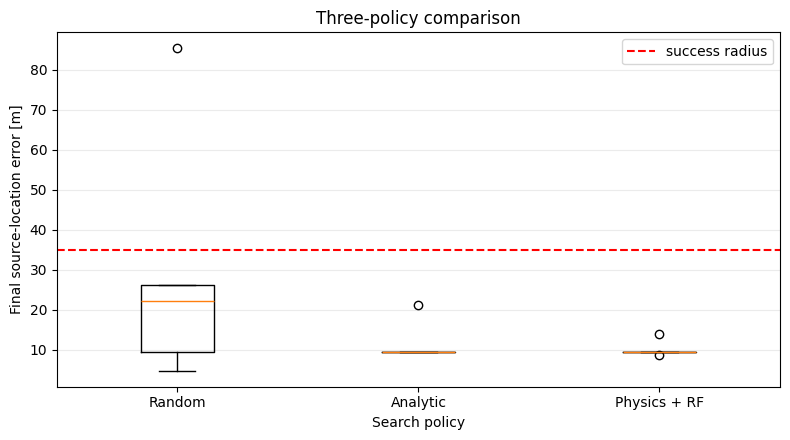

Rendering 1 RANDOM SEARCH
Rendering 2 ANALYTIC MODEL
Rendering 3 PHYSICS + RF RESIDUAL


Video: /content/auv_three_policy_current_aligned.mp4


In [ ]:
cfg, models, rf_model, missions, benchmark_rows, video_path, last_frame = main()

from IPython.display import Video, display
from PIL import Image
Image.fromarray(last_frame).save("/content/three_policy_current_aligned_last_frame.png")
display(Video(str(video_path), embed=True))


## 出力
- `/content/auv_three_policy_current_aligned.mp4`
- `/content/three_policy_current_aligned_last_frame.png`
- `/content/three_policy_error.png`
